# D4 · Image Contrast Examples

**Part:** D – Contrast · **Reading time:** ~40 min · **Pass 1 overview:** [P1.4 Contrast and Image Quality](../pass1_big_picture/P1.4_Contrast_and_Image_Quality.ipynb) · **Refreshers you may want:** [RM6 2D Fourier and images](../refreshers/RM6_2D_Fourier_and_Images.ipynb), [RM5 Fourier pairs and sampling](../refreshers/RM5_Fourier_Pairs_and_Sampling.ipynb)

**Why this chapter matters.** The previous chapters ([D1](../pass2_deep_dive/D1_Basic_Contrast_Mechanisms.ipynb), [D2](../pass2_deep_dive/D2_In_Vivo_Contrast_Mechanisms.ipynb), [D3](../pass2_deep_dive/D3_Gradient_and_Spin_Echoes.ipynb)) gave the formulas. Here you practise the reverse direction, which is what you do in front of a real image: *look at the brightness of known tissues and infer how the image was made*, and *measure signals and infer the tissue parameters*. We use real example images, a simple simulated phantom (port of the original code) and a "read the contrast" exercise.

## Learning goals

1. Describe how various types of MRI contrast are created
    * Identify various image contrasts
2. *(added)* Infer the weighting (T1w, T2w, PDw, FLAIR, STIR, post-contrast) of an image from the relative brightness of reference tissues
3. *(added)* Estimate $T_1$ and $T_2$ from images acquired with different TR and TE, and with two flip angles (variable flip angle method)

## Symbols used in this chapter

| Symbol | Meaning (plain words) | SI unit | Typical value / remark |
|---|---|---|---|
| $S$ | image signal (pixel value, magnitude) | a.u. | |
| $M_0$ | equilibrium magnetization ∝ proton density | normalized | |
| $T_1$, $T_2$, $T_2^*$ | relaxation time constants | s | |
| $TE$, $TR$, $TI$ | echo, repetition, inversion time | s | |
| $\theta$ | flip angle | rad (°) | |
| $E_1=e^{-TR/T_1}$ | shorthand | – | |
| $m(\vec r)$ | image (transverse magnetization at TE) | a.u. | |
| $M(k_x,k_y)$ | k-space data (**not** magnetization here) | a.u. | |
| $k_x,k_y$, $k_r=\sqrt{k_x^2+k_y^2}$ | spatial frequency; radial spatial frequency | m⁻¹ (here: cycles/pixel) | |
| $\mathrm{circ}(r)$, $\mathrm{jinc}(x)=J_1(\pi x)/(\pi x)$ | disk function; its Fourier transform's shape | – | $J_1$: Bessel function of the first kind, order 1 |
| $R$ | disk radius | m (here: fraction of FOV) | |
| $(x_c,y_c)$ | disk centre | fraction of FOV | |
| $\sigma_n$ | noise standard deviation | a.u. | |
| $C$ | contrast-agent concentration | mM | |

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))   # make ../mri_tools.py importable
import numpy as np
import matplotlib.pyplot as plt
import mri_tools as mt
mt.setup_plots()
%matplotlib inline

## 1. Real image contrast examples

A practical reading recipe – check the **reference tissues** first:

| tissue | T1w | T2w | PDw | FLAIR | STIR | T1w + Gd |
|---|---|---|---|---|---|---|
| CSF / free fluid | dark | **bright** | grey (≈ tissue) | **dark** | bright | dark |
| WM vs GM (brain) | WM > GM | GM > WM | GM ≳ WM (low contrast) | GM > WM | GM > WM | WM > GM |
| fat (scalp, marrow) | bright | bright on FSE, intermediate on SE | bright | bright-ish | **dark** | bright (unless fat-sat) |
| edema / most lesions | dark | bright | bright | **bright** | bright | enhancing if blood–brain barrier broken |
| vessels with flow | dark (flow void) on SE | dark (flow void) | dark | dark | dark | bright (enhanced) |

### Example 1 – brain (from Pauly and Gold)

![Brain contrast examples (from Pauly and Gold): top row three different weightings of the same slice, bottom row a slice before and after contrast](../images/contrast_brain_example.png)

**Exercise:** name the weighting of each of the five images before opening the answer.

<details><summary>Answer (our reading – acquisition parameters are not given in the source)</summary>

* **Top left – PD-weighted:** brain bright overall, GM slightly brighter than WM, CSF in the ventricles not dark and not much brighter than tissue, low overall contrast.
* **Top middle – $T_1$-weighted:** CSF dark, WM slightly brighter than GM, vessels dark.
* **Top right – $T_2$-weighted:** CSF very bright, GM brighter than WM.
* **Bottom left – $T_1$-weighted, pre-contrast:** subtle abnormality in the right hemisphere (left side of the image).
* **Bottom right – $T_1$-weighted after gadolinium:** a strongly enhancing (bright) lesion – contrast agent has leaked through a broken blood–brain barrier and shortened $T_1$ ([D2](../pass2_deep_dive/D2_In_Vivo_Contrast_Mechanisms.ipynb)).

</details>

> **TODO (polish):** confirm the exact sequences of the Pauly & Gold examples (top-left PD vs. other long-TR/short-TE variant).

### Example 2 – many contrasts of one brain (from Vasily Yarnykh)

![Brain contrast examples from Vasily Yarnykh: many different contrasts of the same brain](../images/contrast_brain_example-all.png)

<details><summary>Answer for the top row (our reading)</summary>

From left to right: **PD-weighted** (CSF grey, low contrast), **$T_2$-weighted** (CSF bright), **$T_1$-weighted** 3D gradient echo (strong WM/GM contrast, CSF black), **FLAIR** (CSF dark but periventricular lesions bright), and an **angiogram/venogram**-type projection (vessels bright). The bottom row shows more specialised contrasts and quantitative maps (e.g. diffusion- and magnetization-transfer-based maps); without the acquisition details we do not label them individually.

</details>

> **TODO (polish):** identify the bottom-row images of the Yarnykh figure from the original source.

### Example 3 – knee

![Knee: T1-weighted, proton-density-weighted and T2-weighted (turbo) spin-echo images with TE/TR shown in the overlays](../images/contrast_knee_example.png)

Here the parameters are printed in the overlays: **T1w** TE = 20 ms, TR = 581 ms; **PDw** TE = 30 ms, TR = 3681 ms; **T2w** TE = 100 ms, TR = 3223 ms (all turbo spin echo, "aTSE/TSE"). Check them against the D1 table: short TR/short TE, long TR/short TE, long TR/long TE. Notice that bone marrow (fat) is bright on all three – on fast-spin-echo $T_2$w images fat stays bright (J-coupling effects in the CPMG train), which is why fat suppression is so often added. The bright lesion in the tibia on PDw and T2w indicates fluid (edema).

In [2]:
# Predicted relative signals (spin-echo formula) for the knee protocols at ~1.5 T
tissues = {"fat (marrow)": (0.9, 0.26, 0.08), "muscle": (0.75, 0.87, 0.05), "fluid/edema": (1.0, 3.0, 1.0),
           "cartilage": (0.7, 1.0, 0.04)}
protocols = {"T1w TE20/TR581": (0.020, 0.581), "PDw TE30/TR3681": (0.030, 3.681), "T2w TE100/TR3223": (0.100, 3.223)}
print(f"{'tissue':14s}" + "".join(f"{p:>18s}" for p in protocols))
for name, (M0, T1, T2) in tissues.items():
    print(f"{name:14s}" + "".join(f"{mt.spin_echo_signal(TE, TR, T1, T2, M0):18.2f}" for TE, TR in protocols.values()))

tissue            T1w TE20/TR581   PDw TE30/TR3681  T2w TE100/TR3223
fat (marrow)                0.63              0.62              0.26
muscle                      0.24              0.41              0.10
fluid/edema                 0.17              0.69              0.60
cartilage                   0.19              0.32              0.06


*Interpretation:* fat brightest on T1w, fluid dark on T1w but brightest on T2w, cartilage and muscle intermediate/dark at long TE – consistent with the images (the simple SE model underestimates fat on the FSE T2w image, see above).

## 2. Simple contrast phantom (port of the original code)

Below is a simple contrast phantom consisting of three disks, each with a different $T_1$ and $T_2$. The k-space data are computed **analytically**: the 2D Fourier transform of a disk (circ function) of radius $R$ is a jinc,

$$\mathcal F\{\mathrm{circ}(r/R)\}(k_r)=\pi R^2\cdot 2\,\mathrm{jinc}(2Rk_r),\qquad \mathrm{jinc}(x)=\frac{J_1(\pi x)}{\pi x}.$$

*In words:* a disk in the image becomes a ring-like, radially symmetric oscillating pattern in k-space (the circular analogue of rect ↔ sinc); a shift of the disk centre to $(x_c,y_c)$ multiplies it by the linear phase $e^{-i2\pi(k_xx_c+k_yy_c)}$ ([RM4](../refreshers/RM4_Fourier_Properties.ipynb)),
where $k_r$ is the radial spatial frequency and $J_1$ the Bessel function of order 1. This is exactly what `mt.disk_phantom_kspace` computes (the original used `scipy.special.j1` inline). Each disk's k-space is multiplied by its signal from the spoiled-gradient-echo equation with a 90° flip, `mt.spoiled_gre_signal` (here with $T_2^*=T_2$, as in the original).

### Challenge yourself!

Based on the images and TE/TR values below, can you estimate the $T_1$ and $T_2$ relaxation times of the three objects?

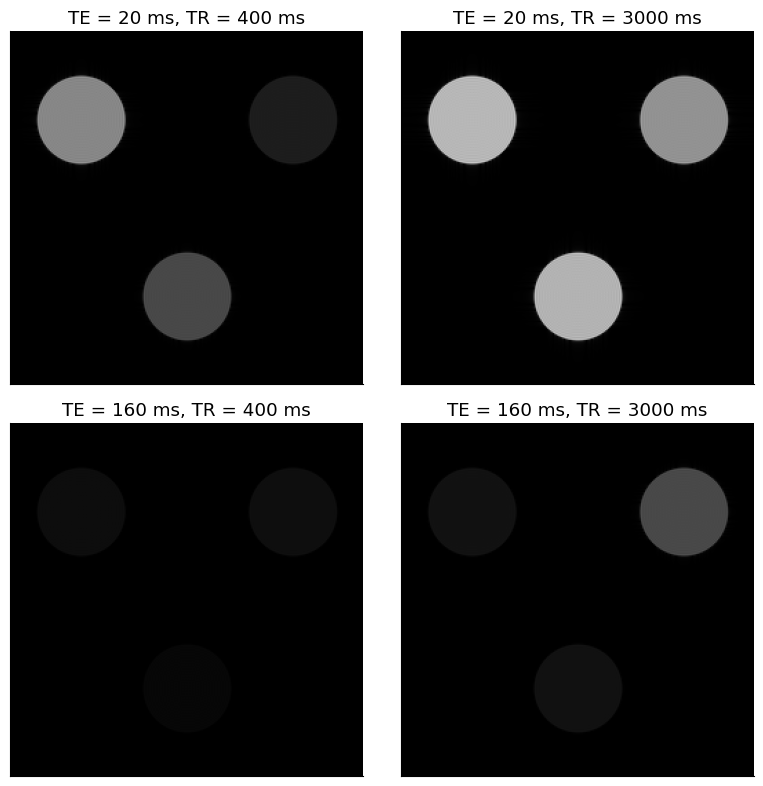

In [3]:
# Port of the original contrast-phantom code using mt.disk_phantom_kspace and mt.spoiled_gre_signal
N = 256
centers = [(-0.3, -0.25), (0.0, 0.25), (0.3, -0.25)]   # disk centres (fraction of FOV)
radius = 0.125                                          # disk radius (fraction of FOV); original r = 1/64 in k-units
M0s = np.array([1.0, 1.0, 1.0])
T1s = np.array([0.3, 0.8, 3.0])                          # [s]
T2s = np.array([0.06, 0.06, 0.2])                        # [s]
flip = np.deg2rad(90)
TEs = [0.020, 0.160]                                     # [s]
TRs = [0.400, 3.000]                                     # [s]

imgs = {}
fig, axs = plt.subplots(2, 2, figsize=(8, 8))
for i, TE in enumerate(TEs):
    for j, TR in enumerate(TRs):
        vals = mt.spoiled_gre_signal(flip, TE, TR, T1s, T2s, M0s)
        K = mt.disk_phantom_kspace(N, centers=centers, radius=radius, values=vals)
        m = mt.ifft2c(K)
        imgs[(TE, TR)] = np.abs(m)
        mt.show_image(m, ax=axs[i, j], title=f"TE = {TE*1e3:.0f} ms, TR = {TR*1e3:.0f} ms", vmin=0, vmax=1)
plt.tight_layout(); plt.show()

*Interpretation:* at TE 20/TR 3000 (PD-like) all disks look equal; at short TR the long-$T_1$ disk fades; at long TE the long-$T_2$ disk stays bright. (Note the faint ringing at the disk edges: the analytic k-space is truncated at $|k|\le N/2$ – Gibbs ringing, [G3](../pass2_deep_dive/G3_Cartesian_Image_Characteristics.ipynb).)

<details><summary>Answer: how to estimate $T_1$ and $T_2$ from these four images</summary>

* **$T_2$** from the two TEs at the same (long) TR: $S_1/S_2=e^{-(TE_1-TE_2)/T_2}$ ⇒ $T_2=(TE_2-TE_1)/\ln(S_1/S_2)$.
* **$T_1$** from the two TRs at the same (short) TE: $S(TR_1)/S(TR_2)=(1-e^{-TR_1/T_1})/(1-e^{-TR_2/T_1})$ – solve numerically for $T_1$ (one equation, one unknown).
* True values: $T_1$ = 300, 800, 3000 ms; $T_2$ = 60, 60, 200 ms. The next cell does this with region-of-interest (ROI) means. Note that TR = 3000 ms is not ≫ $T_1$ = 3000 ms, which is why the formula with both TRs (not just a ratio to $M_0$) is needed.

</details>

In [4]:
# Estimate T1 and T2 from ROI means in the four images
from scipy.optimize import brentq
yy, xx = np.mgrid[0:N, 0:N]
def roi_mean(img, c, r_pix=12):
    cx, cy = N // 2 + c[0] * N, N // 2 + c[1] * N
    return img[(xx - cx)**2 + (yy - cy)**2 < r_pix**2].mean()
for d, c in enumerate(centers):
    S = {key: roi_mean(im, c) for key, im in imgs.items()}
    T2_est = (TEs[1] - TEs[0]) / np.log(S[(TEs[0], TRs[1])] / S[(TEs[1], TRs[1])])
    ratio = S[(TEs[0], TRs[0])] / S[(TEs[0], TRs[1])]
    T1_est = brentq(lambda T1: (1 - np.exp(-TRs[0] / T1)) / (1 - np.exp(-TRs[1] / T1)) - ratio, 0.01, 20)
    print(f"disk {d}: T1 est {T1_est*1e3:6.0f} ms (true {T1s[d]*1e3:.0f}),  T2 est {T2_est*1e3:5.0f} ms (true {T2s[d]*1e3:.0f})")

disk 0: T1 est    300 ms (true 300),  T2 est    60 ms (true 60)
disk 1: T1 est    800 ms (true 800),  T2 est    60 ms (true 60)
disk 2: T1 est   3000 ms (true 3000),  T2 est   200 ms (true 200)


*Interpretation:* the estimates match the true values closely; small deviations come from the ringing inside the ROIs.

> **TODO (polish):** add the second phantom from `contrast_phantom.m` ($T_1$ = 500, 500, 3000 ms; $T_2$ = 20, 50, 100 ms; TE 50, TR 500) as an extra challenge.

## 3. "Read the contrast" exercise (added)

Six images of the tissue phantom (`mt.tissue_phantom`: fat-like rim, WM-like background, GM-like ellipse, two dark CSF ellipses, small lesions) were made with six *hidden* protocols and noise. Labels A–F are shuffled. For each image, decide: T1w, T2w, PDw, FLAIR, STIR, or T1w after gadolinium.

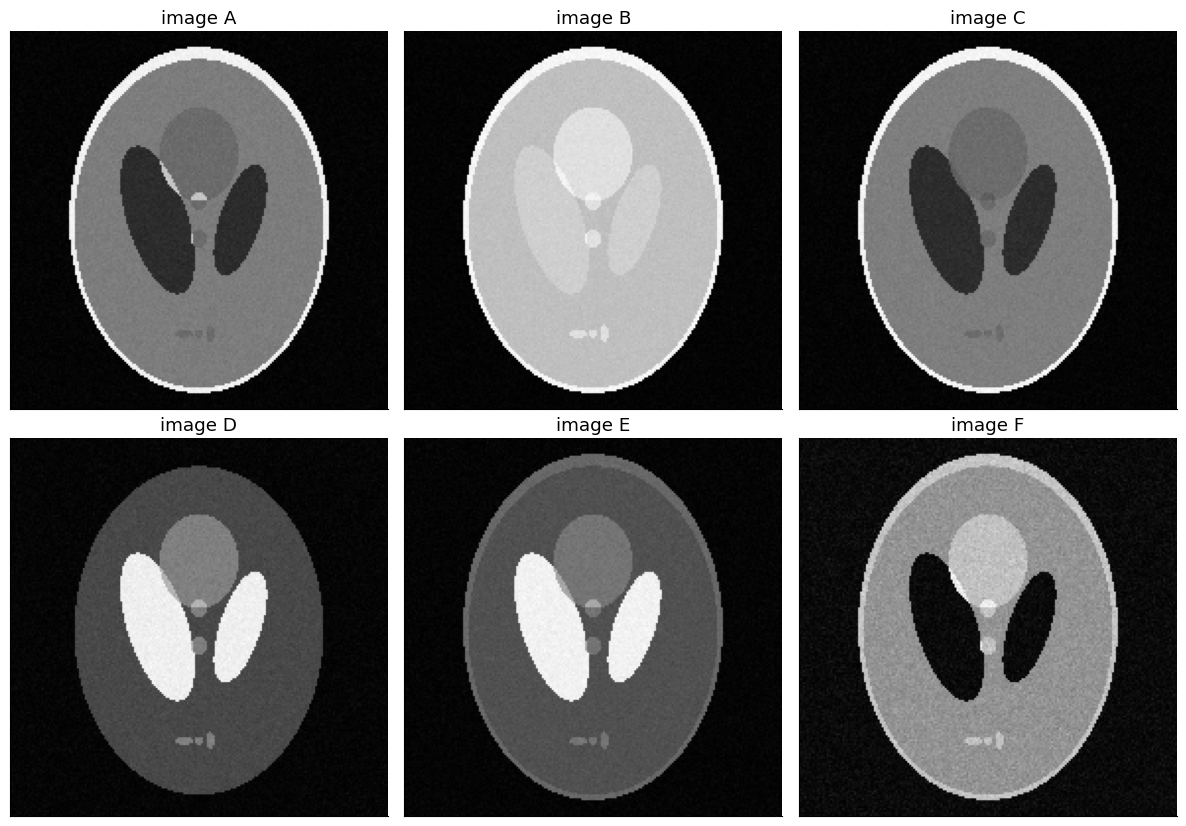

In [5]:
ph = mt.tissue_phantom(192)
M0, T1m, T2m, lab = ph["M0"], ph["T1"], ph["T2"], ph["labels"]
head = lab > 0
Cgd = np.where(lab == 5, 0.4, 0.0)                         # 0.4 mM Gd in lesions for the post-contrast image
T1gd = 1 / (1 / T1m + 4.0 * Cgd); T2gd = 1 / (1 / T2m + 5.0 * Cgd)
hidden = {
    "T1w SE (TR 500, TE 15)":          mt.spin_echo_signal(0.015, 0.5, T1m, T2m, M0),
    "T2w SE (TR 4000, TE 100)":        mt.spin_echo_signal(0.100, 4.0, T1m, T2m, M0),
    "PDw SE (TR 4000, TE 15)":         mt.spin_echo_signal(0.015, 4.0, T1m, T2m, M0),
    "FLAIR (TI 2370, TR 9000, TE 110)": np.abs(mt.inversion_recovery_signal(2.37, 9.0, 0.110, T1m, T2m, M0)),
    "STIR (TI 180, TR 4000, TE 60)":   np.abs(mt.inversion_recovery_signal(0.18, 4.0, 0.060, T1m, T2m, M0)),
    "T1w SE + Gd":                     mt.spin_echo_signal(0.015, 0.5, T1gd, T2gd, M0),
}
rng = np.random.default_rng(7)
order = rng.permutation(len(hidden))
names = list(hidden)
letters = "ABCDEF"
fig, axs = plt.subplots(2, 3, figsize=(12, 8.4))
for ax, L, idx in zip(axs.flat, letters, order):
    img = np.abs(mt.add_complex_noise(hidden[names[idx]] * head, 0.01, rng))
    mt.show_image(img, ax=ax, title=f"image {L}")
plt.tight_layout(); plt.show()

<details><summary>Answers with explanations</summary>

Run the next cell to print which letter is which protocol. Explanations by protocol:

* **T1w SE:** CSF ellipses dark, rim (fat-like, short $T_1$) brightest, background (WM-like) brighter than the GM-like ellipse, lesions barely visible.
* **T1w SE + Gd:** identical to T1w except the small lesions are now **bright** (enhancement).
* **T2w SE:** CSF ellipses brightest, GM-like ellipse brighter than background, lesions bright.
* **PDw SE:** everything fairly bright, low contrast; GM slightly brighter than WM; CSF only similar to GM, because TR = 4 s is not long compared with CSF's $T_1$ ≈ 4 s.
* **FLAIR:** looks $T_2$-weighted but the CSF ellipses are **black**; lesions stay bright – the typical FLAIR signature.
* **STIR:** like a $T_2$/PD-weighted image but the fat-like rim is **black**.

</details>

In [6]:
# Reveal the answers and show mean signal per tissue for each image
tissue_names = {1: "fat", 2: "WM", 3: "GM", 4: "CSF", 5: "lesion"}
for L, idx in zip(letters, order):
    img = hidden[names[idx]] * head
    vals = ", ".join(f"{tissue_names[k]} {img[lab == k].mean():.2f}" for k in tissue_names)
    print(f"image {L}: {names[idx]:34s} | {vals}")

image A: T1w SE + Gd                        | fat 0.64, WM 0.33, GM 0.28, CSF 0.12, lesion 0.52
image B: PDw SE (TR 4000, TE 15)            | fat 0.75, WM 0.58, GM 0.68, CSF 0.63, lesion 0.73
image C: T1w SE (TR 500, TE 15)             | fat 0.64, WM 0.33, GM 0.28, CSF 0.12, lesion 0.25
image D: STIR (TI 180, TR 4000, TE 60)      | fat 0.00, WM 0.16, GM 0.28, CSF 0.53, lesion 0.40
image E: T2w SE (TR 4000, TE 100)           | fat 0.26, WM 0.20, GM 0.29, CSF 0.60, lesion 0.42
image F: FLAIR (TI 2370, TR 9000, TE 110)   | fat 0.23, WM 0.17, GM 0.22, CSF 0.00, lesion 0.28


*Interpretation:* each protocol is uniquely identified by two or three reference tissues: CSF (dark/bright/nulled), fat (bright/nulled) and the lesions (enhancing or not).

## 4. Quantitative extension: $T_1$ map from two flip angles (variable flip angle)

Instead of weighting, we can *measure* $T_1$ pixel by pixel. With a spoiled gradient echo, the signal equation can be rearranged (divide $S=M_0\sin\theta\,(1-E_1)/(1-E_1\cos\theta)$ by $\sin\theta$ and collect terms):

$$\frac{S}{\sin\theta}=E_1\,\frac{S}{\tan\theta}+M_0(1-E_1).$$

*In words:* plotted as $y=S/\sin\theta$ against $x=S/\tan\theta$, the points for different flip angles lie on a straight line with slope $E_1$, so $T_1=-TR/\ln(\text{slope})$ (method known as DESPOT1 / variable flip angle),
where $\theta$ is the flip angle, TR the repetition time and $E_1=e^{-TR/T_1}$. Two flip angles suffice.

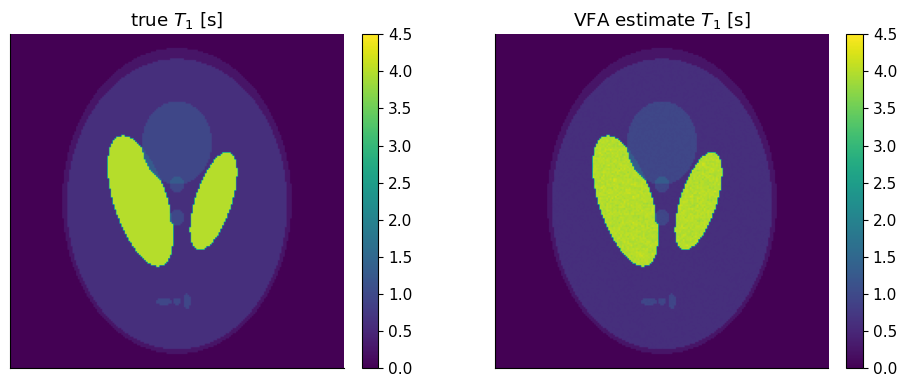

fat    : true    260 ms, estimated median    260 ms
WM     : true    600 ms, estimated median    600 ms
GM     : true    950 ms, estimated median    950 ms
CSF    : true   4000 ms, estimated median   4000 ms
lesion : true   1300 ms, estimated median   1301 ms


In [7]:
# VFA T1 mapping on the phantom: two flip angles, TR = 15 ms, with noise
TR = 0.015
th = np.deg2rad([3.0, 17.0])
S = [np.abs(mt.add_complex_noise(mt.spoiled_gre_signal(t, 0.0, TR, T1m, T2m, M0) * head, 2e-4, rng)) for t in th]
x = [s / np.tan(t) for s, t in zip(S, th)]; y = [s / np.sin(t) for s, t in zip(S, th)]
slope = (y[1] - y[0]) / (x[1] - x[0] + 1e-12)
T1_map = np.where(head, -TR / np.log(np.clip(slope, 1e-6, 0.999999)), 0)
fig, axs = plt.subplots(1, 2, figsize=(10, 4))
mt.show_image(T1m * head, ax=axs[0], title="true $T_1$ [s]", cmap="viridis", vmin=0, vmax=4.5, colorbar=True)
mt.show_image(T1_map, ax=axs[1], title="VFA estimate $T_1$ [s]", cmap="viridis", vmin=0, vmax=4.5, colorbar=True)
plt.tight_layout(); plt.show()
for k, n in tissue_names.items():
    print(f"{n:7s}: true {T1m[lab==k].mean()*1e3:6.0f} ms, estimated median {np.median(T1_map[lab==k])*1e3:6.0f} ms")

*Interpretation:* with this low noise level all $T_1$ values are recovered (medians); long-$T_1$ CSF is the most noise-sensitive because TR/$T_1$ is tiny and the slope is close to 1.

> **TODO (polish):** show the VFA estimate at a realistic noise level and plot per-tissue error bars.

> **🔧 Engineering reality:** VFA $T_1$ maps are only as good as the flip angles. At 3 T the actual flip angle differs from the nominal one by ±20–30 % because of $B_1^+$ inhomogeneity, and since the estimate depends on $\theta$ roughly quadratically, $T_1$ errors of 40 % or more are possible without a separate $B_1^+$ map. Incomplete spoiling ([D1](../pass2_deep_dive/D1_Basic_Contrast_Mechanisms.ipynb), Section 7) biases it further.

> **TODO (polish):** add a $B_1^+$-error demonstration (scale the true flip angle by 0.8–1.2 and show the $T_1$ bias).

## Key takeaways

* Reading contrast = checking reference tissues: CSF (dark → T1w or FLAIR; bright → T2w), fat (dark → STIR or fat-sat), WM vs GM ordering (WM > GM on T1w, GM > WM on T2w/PDw).
* Real protocols list TE/TR in the image overlay – match them to the short/long TR/TE table.
* Gadolinium enhancement is seen as new brightness on T1w images; FLAIR = T2w with nulled CSF.
* An analytic disk phantom (jinc k-space) gives realistic images including truncation ringing.
* With two or more TEs/TRs/flip angles, $T_2$ and $T_1$ can be estimated quantitatively (log-ratio for $T_2$, numerical solve or VFA linearization for $T_1$) – limited by noise, $B_1^+$ errors and spoiling.

## Check your understanding

**1.** An image shows bright CSF, bright lesions, and a black scalp. What is it?

<details><summary>Answer</summary>

**STIR** (fat nulled by inversion, fluid bright). A fat-saturated T2w image looks similar; you'd check the protocol name or TI.

</details>

**2.** In a brain image WM is brighter than GM and CSF is black, but periventricular lesions are bright. T1w or FLAIR?

<details><summary>Answer</summary>

On T1w, lesions are usually dark (long $T_1$). Bright lesions with black CSF point to **FLAIR**; but on FLAIR GM is normally brighter than WM. If WM > GM *and* lesions are bright, consider a T1w image after contrast (enhancing lesions).

</details>

**3.** Two spin-echo images at TR = 4000 ms give a tissue signal of 0.60 (TE = 20 ms) and 0.30 (TE = 80 ms). What is $T_2$?

<details><summary>Answer</summary>

$T_2=(80-20)\,\text{ms}/\ln(0.60/0.30)=60/0.693\approx$ **87 ms**.

</details>

**4.** Why does the analytic jinc phantom show ringing, while a phantom created by FFT of a pixel image of disks might not?

<details><summary>Answer</summary>

The analytic k-space of a sharp-edged disk extends to infinite $k$; we sample only $|k|\le N/2$, i.e. we truncate it, which convolves the image with a sinc-like kernel → Gibbs ringing. An FFT of a pixel image is exactly periodic and band-limited by construction, so its inverse FFT reproduces the pixels without ringing – and therefore hides a real-world effect.

</details>

---
*Adapted and extended from P. Larson, "Principles of MRI" (MIT License), chapter "Image Contrast Examples". Changes: ported the phantom code to `mt.disk_phantom_kspace`/`mt.spoiled_gre_signal`, added the jinc formula with all symbols, a contrast-reading table, answers for the example images and the phantom challenge (with $T_1$/$T_2$ estimation), knee parameter analysis, a shuffled "read the contrast" exercise and VFA $T_1$ mapping.*